# 2.6 — Regressão linear com dados reais: salários (treino × validação)

## Objetivos

- Aplicar o pipeline do 2.5 (`nn.Linear`, `nn.MSELoss`, `optim.SGD`) a um dataset real: salário em função dos anos de experiência.
- Separar os dados em treino e validação (70/30) e acompanhar a função de custo (loss) nos dois conjuntos.
- Organizar o treino em funções `train_epoch` e `validate_epoch`, com `model.train()`, `model.eval()` e `torch.no_grad()`.
- Usar o bias da própria camada (`nn.Linear(1, 1)`) no lugar da coluna de uns.

O problema é o exemplo dos slides: dado o tempo de experiência de um profissional, prever o seu salário. A entrada $x$ é `YearsExperience` (anos de experiência) e a saída $y$ é `Salary` (salário anual; a fonte não informa a moeda). O modelo é a mesma reta dos notebooks anteriores:

$$\hat{y} = w_0 + w_1 x$$

com $w_0$ = bias (intercepto) e $w_1$ = peso. Nos slides: $h_\theta(x) = \theta_0 + \theta_1 x$, com $w_0 = \theta_0$ e $w_1 = \theta_1$.

O que muda em relação ao 2.5: os dados são reais e poucos (30 profissionais), parte deles é separada para validação, e o bias passa a ser um parâmetro da camada.

## Importação das bibliotecas

In [1]:
import io
import pathlib
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## Dados

### Download

Fonte: [Salary Dataset - Simple linear regression](https://www.kaggle.com/datasets/abhishek14398/salary-dataset-simple-linear-regression) (Kaggle). O endpoint público de download do Kaggle entrega o `.zip` sem login. O arquivo `Salary_dataset.csv` tem uma coluna de índice sem nome, `YearsExperience` e `Salary`.

Ele é uma cópia do clássico `Salary_Data.csv`, com 0,1 ano e 1 unidade de salário somados a todas as linhas. Se o Kaggle estiver indisponível, a célula baixa o `Salary_Data.csv` de um repositório público no GitHub. Depois da padronização (abaixo), os dois arquivos dão os mesmos valores, porque somar uma constante não muda a padronização.

O arquivo vai para a pasta `./data`; se já existir, não é baixado de novo.

In [2]:
DATA_DIR = pathlib.Path('data')
DATA_DIR.mkdir(exist_ok=True)

KAGGLE_URL = 'https://www.kaggle.com/api/v1/datasets/download/abhishek14398/salary-dataset-simple-linear-regression'
MIRROR_URL = 'https://raw.githubusercontent.com/krishnaik06/simple-linear-regression/master/Salary_Data.csv'

csv_path = DATA_DIR / 'Salary_dataset.csv'
if not csv_path.exists():
    try:
        with urllib.request.urlopen(KAGGLE_URL, timeout=30) as resp:
            zipfile.ZipFile(io.BytesIO(resp.read())).extract('Salary_dataset.csv', DATA_DIR)
        print('baixado do Kaggle:', csv_path)
    except Exception as e:
        print('Kaggle indisponível (', e, '); usando a cópia do GitHub')
        csv_path = DATA_DIR / 'Salary_Data.csv'
        urllib.request.urlretrieve(MIRROR_URL, csv_path)
print('arquivo:', csv_path)

baixado do Kaggle: data/Salary_dataset.csv
arquivo: data/Salary_dataset.csv


### Leitura

In [3]:
df = pd.read_csv(csv_path)
df = df[['YearsExperience', 'Salary']]   # descarta a coluna de índice, se houver
print('shape:', df.shape)
df.head()

shape: (30, 2)


,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0


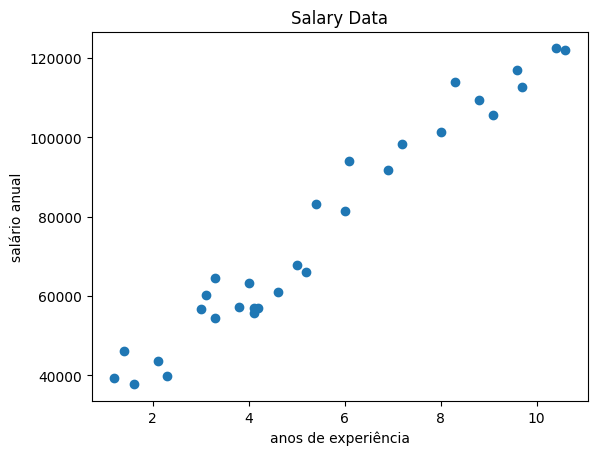

In [4]:
plt.scatter(df['YearsExperience'], df['Salary'])
plt.xlabel('anos de experiência')
plt.ylabel('salário anual')
plt.title('Salary Data')
plt.show()

### Treino × validação

Os parâmetros são ajustados só com o conjunto de treino. O conjunto de validação fica de fora do treino e serve para medir o custo em dados que o modelo não viu: um custo baixo no treino não garante um custo baixo em dados novos.

`train_test_split(..., test_size=0.3, random_state=42)` sorteia 30% das linhas para validação: 21 amostras de treino e 9 de validação. `random_state` fixa o sorteio, para que a divisão seja sempre a mesma. Com só 30 amostras, não separamos um terceiro conjunto (teste).

In [5]:
x_raw = df[['YearsExperience']].to_numpy()   # (30, 1)
y_raw = df[['Salary']].to_numpy()            # (30, 1)

x_train_raw, x_val_raw, y_train_raw, y_val_raw = train_test_split(
    x_raw, y_raw, test_size=0.3, random_state=42)
print('treino:', x_train_raw.shape, ' validação:', x_val_raw.shape)

treino: (21, 1)  validação: (9, 1)


### Normalização

Anos de experiência ficam entre 1 e 11; salários, entre ~37 mil e ~122 mil. Com escalas tão diferentes, o gradiente descendente precisaria de uma taxa de aprendizado minúscula. Padronizamos cada variável (z-score):

$$z = \frac{x - \mu}{\sigma}$$

em que $\mu$ e $\sigma$ são a média e o desvio padrão. O `StandardScaler` do scikit-learn faz essa conta: `fit` calcula $\mu$ e $\sigma$, `transform` aplica a fórmula e `inverse_transform` desfaz.

$\mu$ e $\sigma$ são calculados **só no treino** e depois aplicados à validação. Se fossem calculados com todos os dados, informação da validação entraria no treino (vazamento de dados), e a validação deixaria de representar dados novos.

In [6]:
x_scaler = StandardScaler().fit(x_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

# tensores float32 (sem requires_grad: são dados, não parâmetros)
x_train = torch.from_numpy(x_scaler.transform(x_train_raw)).float()
y_train = torch.from_numpy(y_scaler.transform(y_train_raw)).float()
x_val = torch.from_numpy(x_scaler.transform(x_val_raw)).float()
y_val = torch.from_numpy(y_scaler.transform(y_val_raw)).float()

print('x_train:', x_train.shape, ' y_train:', y_train.shape)
print('x_val:  ', x_val.shape, ' y_val:  ', y_val.shape)

x_train: torch.Size([21, 1])  y_train: torch.Size([21, 1])
x_val:   torch.Size([9, 1])  y_val:   torch.Size([9, 1])


## Modelo

`nn.Linear(1, 1)` tem `bias=True` por padrão e calcula $\hat{y} = w_1 x + w_0$:

- `model.weight`, shape (1, 1), é o peso $w_1$;
- `model.bias`, shape (1,), é o bias $w_0$.

São os mesmos 2 parâmetros dos notebooks anteriores, mas agora não é preciso a coluna de uns (`x_train_bias`): a camada soma o bias. Usamos a inicialização padrão do `nn.Linear`.

In [7]:
model = nn.Linear(1, 1)
print('weight (w1):', model.weight)
print('bias (w0):  ', model.bias)

weight (w1): Parameter containing:
tensor([[-0.9420]], requires_grad=True)
bias (w0):   Parameter containing:
tensor([-0.1962], requires_grad=True)


### Testando o predict da rede

In [8]:
model(torch.ones(5, 1))

tensor([[-1.1382],
        [-1.1382],
        [-1.1382],
        [-1.1382],
        [-1.1382]], grad_fn=<AddmmBackward0>)

In [9]:
model(x_train[:3])

tensor([[ 1.0913],
        [ 0.7119],
        [-0.2882]], grad_fn=<AddmmBackward0>)

## Treinamento

### Função de custo e otimizador

Os mesmos do 2.5.

In [10]:
lr = 0.3
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)   # atualiza weight e bias

### Funções de treino e de validação

O código de uma época vira duas funções:

- `train_epoch` faz um passo de gradiente descendente com todo o conjunto de treino (as 21 amostras de uma vez; aqui uma época é uma iteração. Mini-batches aparecem no 3.3) e devolve o custo;
- `validate_epoch` só calcula o custo na validação, sem atualizar nada.

Duas construções novas:

- `model.train()` e `model.eval()` colocam o modelo em modo de treino ou de avaliação. Para `nn.Linear` não muda nada; muda para camadas como dropout e batch normalization, que se comportam de forma diferente no treino (módulo 4). Usar os dois desde já é o padrão do PyTorch.
- `with torch.no_grad():` desliga o registro do grafo do autograd. Na validação não há `backward()`, então o grafo seria memória e tempo desperdiçados.

In [11]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()            # modo de treino
    optimizer.zero_grad()

    # forward
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)

    # backward e otimizador
    loss.backward()
    optimizer.step()

    return loss.item()       # custo como número Python

In [12]:
def validate_epoch(model, criterion, x_val, y_val):
    model.eval()             # modo de avaliação
    with torch.no_grad():    # sem grafo do autograd: não haverá backward
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

### Laço de treinamento

A cada época: um passo de treino, a medida na validação e o registro dos parâmetros. Observe que `train_loss` é medido no forward, antes do `step()` daquela época, e `val_loss` depois dele.

In [13]:
n_epochs = 120
w0_list = []   # bias
w1_list = []   # peso
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    w0_list.append(model.bias.item())
    w1_list.append(model.weight.item())

    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    train_losses.append(train_loss)

    val_loss = validate_epoch(model, criterion, x_val, y_val)
    val_losses.append(val_loss)

    if (epoch + 1) % 20 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}')

Epoch[20/120], Train Loss: 0.0425, Val Loss: 0.0556
Epoch[40/120], Train Loss: 0.0425, Val Loss: 0.0556
Epoch[60/120], Train Loss: 0.0425, Val Loss: 0.0556
Epoch[80/120], Train Loss: 0.0425, Val Loss: 0.0556
Epoch[100/120], Train Loss: 0.0425, Val Loss: 0.0556
Epoch[120/120], Train Loss: 0.0425, Val Loss: 0.0556


## Avaliação

### Curvas de custo de treino e de validação

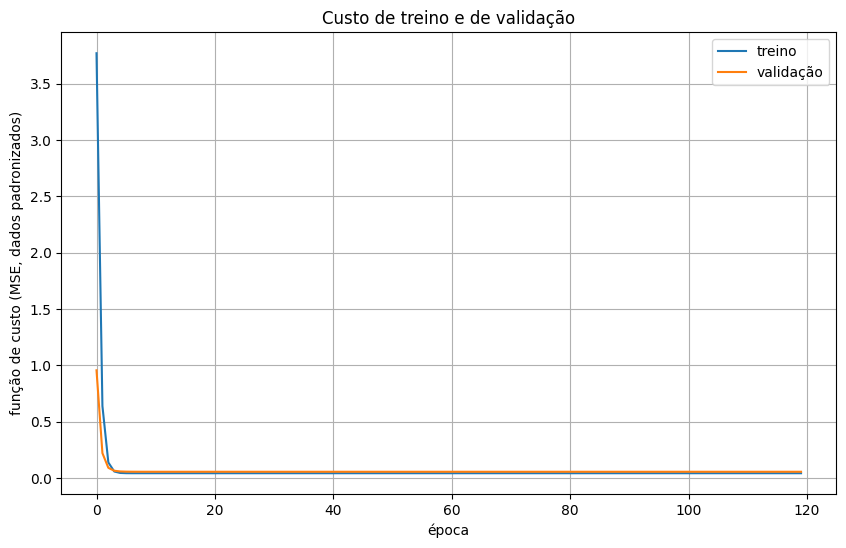

In [14]:
plt.figure(figsize=(10, 6))
plt.plot(range(n_epochs), train_losses, label='treino')
plt.plot(range(n_epochs), val_losses, label='validação')
plt.xlabel('época')
plt.ylabel('função de custo (MSE, dados padronizados)')
plt.title('Custo de treino e de validação')
plt.legend()
plt.grid(True)
plt.show()

### Reta ajustada

A reta é calculada nos dados padronizados e levada de volta à escala original com `inverse_transform`, para ler os eixos em anos e em salário.

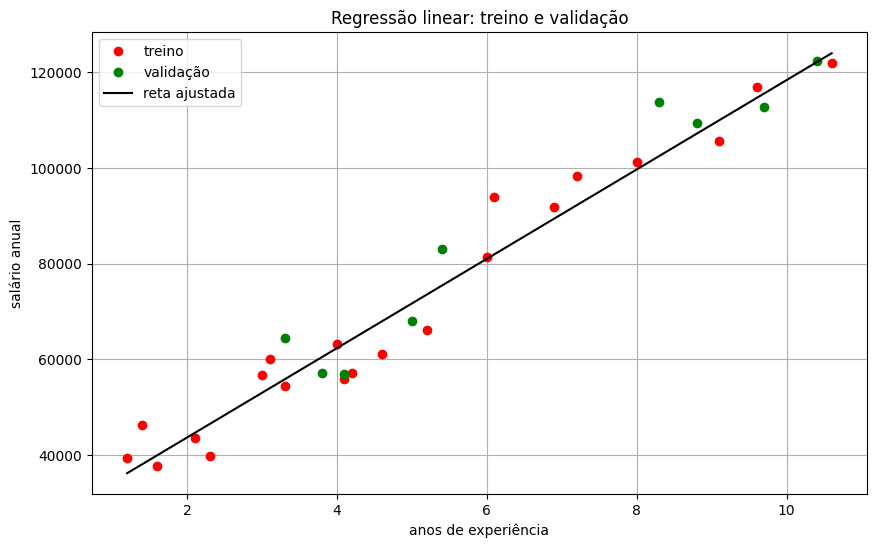

In [15]:
x_grid_raw = np.linspace(x_raw.min(), x_raw.max(), 100).reshape(-1, 1)
x_grid = torch.from_numpy(x_scaler.transform(x_grid_raw)).float()

model.eval()
with torch.no_grad():
    y_grid = model(x_grid)
y_grid_raw = y_scaler.inverse_transform(y_grid.numpy())

plt.figure(figsize=(10, 6))
plt.plot(x_train_raw, y_train_raw, 'ro', label='treino')
plt.plot(x_val_raw, y_val_raw, 'go', label='validação')
plt.plot(x_grid_raw, y_grid_raw, 'k-', label='reta ajustada')
plt.xlabel('anos de experiência')
plt.ylabel('salário anual')
plt.title('Regressão linear: treino e validação')
plt.legend()
plt.grid(True)
plt.show()

### Parâmetros treinados (na escala padronizada)

In [16]:
print('w0 (bias):', model.bias.item())
print('w1 (peso):', model.weight.item())
print(f'MSE final  treino: {train_losses[-1]:.4f}   validação: {val_losses[-1]:.4f}')

w0 (bias): -4.397277209022832e-09
w1 (peso): 0.9784950613975525
MSE final  treino: 0.0425   validação: 0.0556


## Exercícios

### Exercício 1 — Erro em unidades de salário

O MSE acima está na escala padronizada, difícil de interpretar. Calcule a raiz do erro quadrático médio (RMSE) na validação **em unidades de salário**:

$$\text{RMSE} = \sqrt{\frac{1}{M_{val}}\sum_{i=1}^{M_{val}}\left(\hat{y}^{(i)} - y^{(i)}\right)^2}$$

em que $M_{val} = 9$ é o número de amostras de validação. Use `y_scaler.inverse_transform` para levar as previsões de volta à escala original e compare com `y_val_raw`. Guarde o resultado em `rmse_val` e compare com o salário médio.

In [17]:
model.eval()
with torch.no_grad():
    y_val_pred = model(x_val)                                   # previsões padronizadas, (9, 1)
y_val_pred_raw = y_scaler.inverse_transform(y_val_pred.numpy())  # de volta à escala de salário

rmse_val = np.sqrt(np.mean((y_val_pred_raw - y_val_raw) ** 2))
print(f'RMSE de validação: {rmse_val:,.0f}')
print(f'salário médio:     {y_raw.mean():,.0f}')

RMSE de validação: 6,147
salário médio:     76,004


In [18]:
# conferência: RMSE em salário = sqrt(MSE padronizado) * desvio padrão do salário no treino
print(f'sqrt(MSE_val) * sigma_y = {np.sqrt(val_losses[-1]) * y_scaler.scale_[0]:,.0f}  (deve ser ≈ ao RMSE acima)')
print(f'RMSE / salário médio    = {rmse_val / y_raw.mean() * 100:.1f}%')

sqrt(MSE_val) * sigma_y = 6,147  (deve ser ≈ ao RMSE acima)
RMSE / salário médio    = 8.1%


**Resposta:** o RMSE de validação é de cerca de 6.100 em unidades de salário (a fonte não informa a moeda), ou seja, o modelo erra tipicamente perto de 6.100 em torno do salário real. Comparado ao salário médio (~76.000), isso é um erro de cerca de 8%, um erro pequeno: a relação entre anos de experiência e salário é bem linear. A conferência acima mostra que o RMSE é o $\sqrt{\text{MSE}}$ da escala padronizada multiplicado pelo desvio padrão do salário no treino (a padronização só reescala o erro). Com só 9 amostras de validação o valor é uma estimativa ruidosa: outra divisão do treino/validação poderia dar um valor um pouco diferente.

### Exercício 2 — Previsão para um caso novo

Qual salário o modelo prevê para uma pessoa com 5 anos de experiência? Lembre-se de padronizar a entrada com `x_scaler` antes de passá-la ao modelo e de desfazer a padronização da saída. Guarde o valor (um número) em `salario_5`.

In [19]:
anos = np.array([[5.0]])

x_novo = torch.from_numpy(x_scaler.transform(anos)).float()   # 1) padroniza a entrada com o scaler do treino
model.eval()
with torch.no_grad():
    y_novo = model(x_novo)                                    # 2) previsão na escala padronizada
salario_5 = float(y_scaler.inverse_transform(y_novo.numpy())[0, 0])   # 3) volta para a escala de salário

print(f'salário previsto para {anos[0, 0]:.0f} anos: {salario_5:,.0f}')

salário previsto para 5 anos: 71,681


In [20]:
# conferência pela reta na escala original: y = w0' + w1' * x
w1_raw = model.weight.item() * y_scaler.scale_[0] / x_scaler.scale_[0]
w0_raw = y_scaler.mean_[0] + model.bias.item() * y_scaler.scale_[0] - w1_raw * x_scaler.mean_[0]
print(f'reta na escala original: salário = {w0_raw:,.0f} + {w1_raw:,.0f} * anos')
print(f'salário previsto (pela reta): {w0_raw + w1_raw * 5:,.0f}')

reta na escala original: salário = 24,986 + 9,339 * anos
salário previsto (pela reta): 71,681


**Resposta:** o modelo prevê um salário de cerca de 71.700 para 5 anos de experiência (valor exato impresso acima). É importante padronizar a entrada com o `x_scaler` **ajustado no treino** (e não ajustar um scaler novo) e desfazer a padronização da saída com o `y_scaler`; se passássemos `5.0` direto ao modelo, ele o interpretaria como 5 desvios padrão acima da média (um valor absurdo). A célula de conferência obtém o mesmo valor aplicando a reta na escala original, cujos coeficientes são $w_1' = w_1 \sigma_y/\sigma_x$ e $w_0' = \mu_y + w_0\sigma_y - w_1'\mu_x$.

### Exercício 3 — Taxa de aprendizado

Antes de executar, preveja: o que acontece com as curvas de validação se a taxa de aprendizado for 0,01? E 1,1?

Para cada `lr` em `[0.01, 0.1, 0.3, 1.1]`, crie um modelo novo (`torch.manual_seed(1234)` antes de `nn.Linear(1, 1)`, para todos partirem do mesmo ponto) e um otimizador novo, treine por `n_epochs` épocas com `train_epoch`/`validate_epoch` e plote as curvas de custo de validação no mesmo gráfico (use `plt.yscale('log')`). Qual valor você escolheria e por quê?

**Previsão (antes de executar):**

- **`lr = 0,01`:** convergência muito lenta. Cada passo é minúsculo, então em 120 épocas a curva de validação cai devagar e provavelmente não chega ao mínimo.
- **`lr = 1,1`:** divergência. Como os dados estão padronizados, o custo é uma parábola cuja curvatura é 2 em cada parâmetro, e o gradiente descendente só é estável para `lr < 1,0` (a cada passo o erro é multiplicado por $|1 - 2\,\text{lr}|$, que para 1,1 vale 1,2 > 1). Então o erro **cresce** a cada época e o custo explode.
- `lr = 0,1` deve convergir bem, e `lr = 0,3` ainda mais rápido.

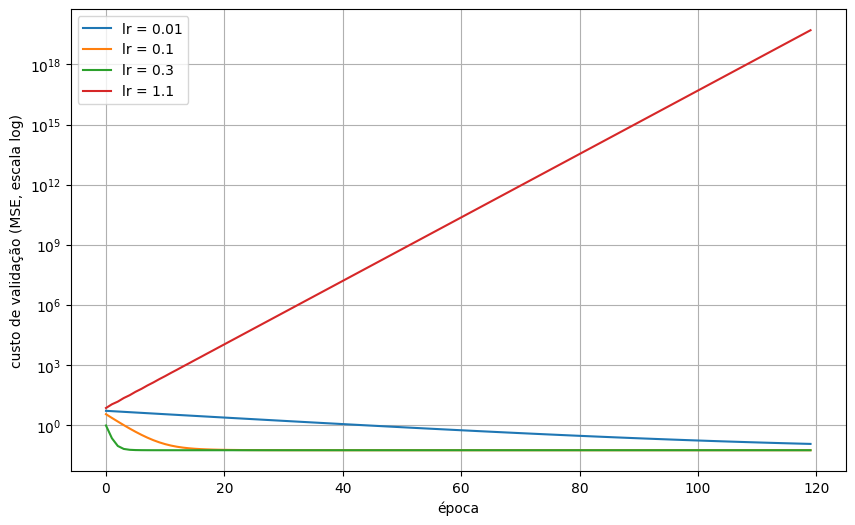

lr = 0.01   custo de validação: época 1 = 5.15   época 20 = 2.47   época 120 = 0.115
lr = 0.1    custo de validação: época 1 = 3.48   época 20 = 0.0588   época 120 = 0.0556
lr = 0.3    custo de validação: época 1 = 0.956   época 20 = 0.0556   época 120 = 0.0556
lr = 1.1    custo de validação: época 1 = 7.11   época 20 = 7.47e+03   época 120 = 5.12e+19


In [21]:
lr_list = [0.01, 0.1, 0.3, 1.1]
resultados = {}

plt.figure(figsize=(10, 6))
for lr_i in lr_list:
    torch.manual_seed(1234)                        # mesmo ponto de partida para todos
    m = nn.Linear(1, 1)
    opt = optim.SGD(m.parameters(), lr=lr_i)
    val_i = []
    for epoch in range(n_epochs):
        train_epoch(m, opt, criterion, x_train, y_train)
        val_i.append(validate_epoch(m, criterion, x_val, y_val))
    resultados[lr_i] = val_i
    plt.plot(range(n_epochs), val_i, label=f'lr = {lr_i}')

plt.yscale('log')
plt.xlabel('época')
plt.ylabel('custo de validação (MSE, escala log)')
plt.legend()
plt.grid(True)
plt.show()

for lr_i, v in resultados.items():
    print(f'lr = {lr_i:<5}  custo de validação: época 1 = {v[0]:.3g}   época 20 = {v[19]:.3g}   época {n_epochs} = {v[-1]:.3g}')

**Resposta:**

- **`lr = 0,01`:** converge, mas muito devagar: após 120 épocas o custo de validação ainda é 0,115, mais que o dobro do mínimo (0,056), e a curva ainda está descendo. Seria preciso muito mais épocas.
- **`lr = 0,1`:** converge de forma suave e estável, chegando ao mínimo (0,056) em algumas dezenas de épocas: na época 20 o custo já é 0,059.
- **`lr = 0,3`:** converge mais rápido: na época 20 o custo já está no mínimo (0,0556) e a curva é estável. A taxa é grande, mas ainda abaixo do limite de estabilidade.
- **`lr = 1,1`:** diverge, como previsto: o custo **aumenta** a cada época (cresce exponencialmente, daí o uso da escala logarítmica) e termina em valores astronômicos (da ordem de $10^{19}$ na época 120).

**Escolha: `lr = 0,3`.** Dentre os valores testados é o que chega ao mínimo mais rápido sem instabilidade. O `0,01` é seguro mas lento demais para as 120 épocas; o `0,1` também serve, só que mais devagar; o `1,1` é inutilizável. Um valor muito próximo do limite (`lr = 1,0` para estes dados padronizados) é arriscado, pois qualquer mudança nos dados ou na escala pode levá-lo à divergência, então escolhemos um valor com folga.

Para este problema particular, a previsão se confirmou: `0,01` foi lento e `1,1` divergiu.

### Exercício 4 — Trajetória dos parâmetros

As listas `w0_list` (bias) e `w1_list` (peso) foram preenchidas no laço de treinamento. Faça o gráfico da trajetória de $(w_0, w_1)$ com setas, como nos notebooks 2.4 e 2.5, e marque a solução analítica (equação normal com uma coluna de uns, calculada com os dados de **treino**). Dica: como os eixos têm escalas bem diferentes, `plt.arrow` deforma as pontas das setas; `plt.annotate('', xy=(w0, w1), xytext=(w0_old, w1_old), arrowprops=dict(arrowstyle='->'))` desenha a seta sem deformação. Por que o $w_0$ ótimo é praticamente zero?

In [22]:
# solução analítica (equação normal) com os dados de treino padronizados
x_bias = torch.cat([torch.ones(x_train.shape[0], 1), x_train], dim=1)   # (21, 2): coluna de uns + x
w_opt = torch.inverse(x_bias.t().mm(x_bias)).mm(x_bias.t()).mm(y_train)  # (2, 1)
w0_opt, w1_opt = w_opt[0, 0].item(), w_opt[1, 0].item()
print(f'w_opt (analítico): w0 = {w0_opt:.2e}, w1 = {w1_opt:.4f}')
print(f'w treinado:        w0 = {w0_list[-1]:.4f}, w1 = {w1_list[-1]:.4f}')

w_opt (analítico): w0 = 0.00e+00, w1 = 0.9785
w treinado:        w0 = -0.0000, w1 = 0.9785


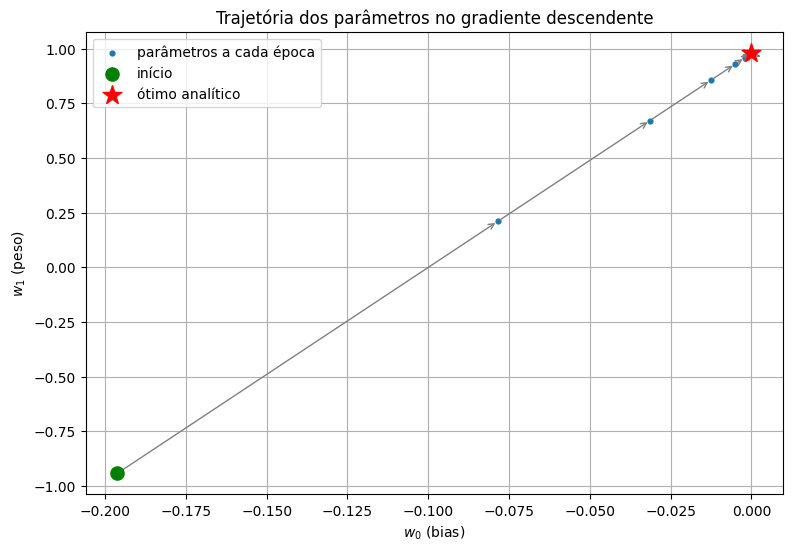

In [23]:
plt.figure(figsize=(9, 6))
plt.scatter(w0_list, w1_list, s=12, label='parâmetros a cada época')

w0_old = w1_old = None
for (w0, w1) in zip(w0_list, w1_list):
    if w0_old is not None:
        plt.annotate('', xy=(w0, w1), xytext=(w0_old, w1_old),
                     arrowprops=dict(arrowstyle='->', color='gray'))
    w0_old, w1_old = w0, w1

plt.scatter(w0_list[0], w1_list[0], c='green', s=90, label='início', zorder=3)
plt.scatter(w0_opt, w1_opt, c='red', s=200, marker='*', label='ótimo analítico', zorder=4)
plt.xlabel('$w_0$ (bias)')
plt.ylabel('$w_1$ (peso)')
plt.title('Trajetória dos parâmetros no gradiente descendente')
plt.legend()
plt.grid(True)
plt.show()

In [24]:
# por que w0 ótimo ≈ 0? as médias das variáveis padronizadas do treino:
print('média de x_train padronizado:', x_train.mean().item())
print('média de y_train padronizado:', y_train.mean().item())
print('w0 = média(y) - w1 * média(x) =', y_train.mean().item() - w1_opt * x_train.mean().item())

média de x_train padronizado: 2.838316470743507e-09
média de y_train padronizado: 0.0
w0 = média(y) - w1 * média(x) = -2.7772788184826975e-09


**Resposta:** a trajetória parte do ponto inicial (valores aleatórios da inicialização padrão do `nn.Linear`) e se aproxima do ótimo analítico (estrela vermelha), com passos longos no início e cada vez menores perto do mínimo.

O $w_0$ ótimo é praticamente zero porque os dados foram padronizados: **as médias de $x$ e de $y$ no treino são zero**. Para uma regressão linear, o bias ótimo é $w_0 = \bar{y} - w_1 \bar{x}$ (a reta ótima sempre passa pelo ponto das médias $(\bar{x}, \bar{y})$). Com $\bar{x} = \bar{y} = 0$, resulta $w_0 = 0$, qualquer que seja $w_1$. O valor impresso acima não é exatamente zero só por arredondamento numérico de `float32`. Em outras palavras, a padronização "centra" os dados na origem, então a reta ajustada passa pela origem e o bias não precisa deslocá-la.

Isso também explica a forma da trajetória: o $w_0$ inicial (aleatório) é "puxado" para 0 e $w_1$ para o seu valor ótimo (próximo de 1, a correlação entre anos de experiência e salário).

## Aprendizados

- Num dataset real, os parâmetros são ajustados só com o treino; a validação mede o custo em dados que o modelo não viu.
- A normalização também é ajustada só no treino (`fit`) e depois aplicada à validação (`transform`), para evitar vazamento de dados; `inverse_transform` traz as previsões de volta para a unidade original.
- `train_epoch`/`validate_epoch` separam o passo de treino (com `backward()` e `step()`) da avaliação (`model.eval()` e `torch.no_grad()`).
- `nn.Linear(1, 1)` tem o bias embutido: `model.bias` é $w_0$ e `model.weight` é $w_1$.
- A taxa de aprendizado decide entre convergência lenta, rápida ou divergência; a curva de validação mostra o efeito.